## MyAnimeList

In [ ]:
import requests
from bs4 import BeautifulSoup
import pandas as pd
import re
import time
from google.colab import files

HEADERS = {
    'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/115.0.0.0 Safari/537.36'
}

# Configure pagination constants
LIMIT_STEP = 50
MAX_LIMIT = 30650
BASE_URL = "https://myanimelist.net/topanime.php?limit={}"

You can configure `PAGES_TO_SCRAPE = 614` in the execution cell below to scrape all 30,650 items.

In [ ]:
30*50

#Detailed Full-Scraper with Hover Metadata
This version programmatically visits each individual anime landing URL to fetch all detailed sidebar metadata

In [ ]:
def scrape_page_with_details(limit_val):
    url = BASE_URL.format(limit_val)
    try:
        response = requests.get(url, headers=HEADERS, timeout=10)
        if response.status_code != 200:
            print(f"[Error] Page limit {limit_val} returned {response.status_code}")
            return []
    except Exception as e:
        print(f"[Exception] Failed to fetch {url}: {e}")
        return []

    soup = BeautifulSoup(response.content, 'lxml' if 'lxml' in globals() else 'html.parser')
    rows = soup.find_all('tr', class_='ranking-list')
    detailed_data = []

    for row in rows:
        # 1. Direct row extraction
        rank_span = row.find('span', class_='top-anime-rank-text')
        rank = rank_span.text.strip() if rank_span else 'N/A'

        score_td = row.find('td', class_='score')
        score = score_td.text.strip() if score_td else 'N/A'

        title_link = row.find('a', class_='hoverinfo_trigger')
        if not title_link:
            continue
        title = title_link.text.strip()
        link = title_link.get('href', 'N/A')

        info_div = row.find('div', class_='information di-ib mt4')
        info_text = info_div.text.strip() if info_div else ''
        info_parts = [p.strip() for p in info_text.split('\n') if p.strip()]

        anime_type = 'N/A'
        episodes = 'N/A'
        if info_parts:
            match = re.match(r'^([A-Za-z0-9\s\-]+)\s*\((.*)\)$', info_parts[0])
            if match:
                anime_type = match.group(1).strip()
                episodes = match.group(2).strip()
            else:
                anime_type = info_parts[0]

        # 2. Detailed page elements
        genres, themes, demographics, status, description = 'N/A', 'N/A', 'N/A', 'N/A', 'N/A'
        start_date, end_date = 'N/A', 'N/A'
        alt_english, alt_synonyms, alt_japanese = 'N/A', 'N/A', 'N/A'

        if link != 'N/A':
            try:
                detail_resp = requests.get(link, headers=HEADERS, timeout=7)
                if detail_resp.status_code == 200:
                    detail_soup = BeautifulSoup(detail_resp.content, 'lxml' if 'lxml' in globals() else 'html.parser')

                    # Description (synopsis)
                    desc_elem = detail_soup.find('p', itemprop='description')
                    if desc_elem:
                        description = desc_elem.text.strip()

                    # Target only the relevant sidebar parent
                    sidebar = detail_soup.find('td', class_='borderClass')
                    if sidebar:
                        for spaceit in sidebar.find_all('div', class_='spaceit_pad'):
                            dark_text = spaceit.find('span', class_='dark_text')
                            if not dark_text:
                                continue
                            label = dark_text.text.strip()
                            if 'Status:' in label:
                                status = spaceit.text.replace(label, '').strip()
                            elif 'Aired:' in label:
                                aired_text = spaceit.text.replace(label, '').strip()
                                if 'to' in aired_text:
                                    dates = [d.strip() for d in aired_text.split('to')]
                                    start_date = dates[0] if len(dates) > 0 else 'N/A'
                                    end_date = dates[1] if len(dates) > 1 else 'N/A'
                                else:
                                    start_date = aired_text
                            elif 'Genre' in label:
                                genres = ", ".join([a.text.strip() for a in spaceit.find_all('a')])
                            elif 'Theme' in label:
                                themes = ", ".join([a.text.strip() for a in spaceit.find_all('a')])
                            elif 'Demographic' in label:
                                demographics = ", ".join([a.text.strip() for a in spaceit.find_all('a')])
                            elif 'English:' in label:
                                alt_english = spaceit.text.replace(label, '').strip()
                            elif 'Synonyms:' in label:
                                alt_synonyms = spaceit.text.replace(label, '').strip()
                            elif 'Japanese:' in label:
                                alt_japanese = spaceit.text.replace(label, '').strip()
            except Exception:
                pass

            time.sleep(0.6)  # Reduced delay slightly for optimized crawling

        detailed_data.append({
            'Rank': rank,
            'Title': title,
            'English Title': alt_english,
            'Synonyms': alt_synonyms,
            'Japanese Title': alt_japanese,
            'Type': anime_type,
            'Episodes': episodes,
            'Score': score,
            'Status': status,
            'Start Date': start_date,
            'End Date': end_date,
            'Genres': genres,
            'Themes': themes,
            'Demographics': demographics,
            'Description': description,
            'URL': link
        })

    return detailed_data

### Detailed scrapping

In [86]:
# Scrape 2 pages (100 items) with all metadata fields as an active benchmark
PAGES_TO_SCRAPE = 30

all_detailed_records = []
for i in range(PAGES_TO_SCRAPE):
    limit_val = i * 50
    print(f"Fetching and parsing detailed entries for page limit: {limit_val}...")
    page_records = scrape_page_with_details(limit_val)
    all_detailed_records.extend(page_records)

# Create DataFrame
mal_detailed_df = pd.DataFrame(all_detailed_records)
display(mal_detailed_df.head(10))

# Export and Auto-Download
final_file = 'myanimelist_with_all_metadata.csv'
mal_detailed_df.to_csv(final_file, index=False)
print(f"Successfully saved {len(mal_detailed_df)} detailed entries. Downloading now...")
files.download(final_file)

Fetching and parsing detailed entries for page limit: 0...


KeyboardInterrupt: 

### Scrapping in range

In [ ]:
# Scrape from Page 30 up to Page 400 (indices 30 to 399)
START_PAGE = 30
END_PAGE = 400

part_2_records = []
for i in range(START_PAGE, END_PAGE):
    limit_val = i * 50
    print(f"Fetching and parsing detailed entries for page limit: {limit_val} (Page {i+1}/{END_PAGE})...")
    page_records = scrape_page_with_details(limit_val)
    part_2_records.extend(page_records)

# Create DataFrame
mal_part_2_df = pd.DataFrame(part_2_records)
display(mal_part_2_df.head(10))

# Export and Auto-Download Part 2
part_2_file = 'myanimelist_part_2.csv'
mal_part_2_df.to_csv(part_2_file, index=False)
print(f"Successfully saved {len(mal_part_2_df)} detailed entries for Part 2. Downloading now...")
files.download(part_2_file)

In [ ]:
import pandas as pd
df=pd.DataFrame(all_detailed_records)
print("list converted to dataset")

# Import the scrapped data

In [141]:
import pandas as pd
df=pd.read_csv("myanimelist_with_all_metadata.csv")
print("loaded dataset to dataframe")

loaded dataset to dataframe


# Data cleaning

In [142]:
df.head()

,Rank,Title,English Title,Synonyms,Japanese Title,Type,Episodes,Score,Status,Start Date,End Date,Genres,Themes,Demographics,Description,URL
0,1,NaN,Frieren: Beyond Journey's End,"Frieren at the Funeral, Frieren The Slayer",Ëë¨ÈÄÅ„ÅÆ„Éï„É™„Éº„É¨„É≥,TV,28 eps,9.24,Finished Airing,"Sep 29, 2023","Mar 22, 2024","Adventure, Award Winning, Drama, Fantasy",NaN,Shounen,During their decade-long quest to defeat the D...,https://myanimelist.net/anime/52991/Sousou_no_...
1,2,NaN,Fullmetal Alchemist: Brotherhood,"Hagane no Renkinjutsushi: Fullmetal Alchemist,...",Èãº„ÅÆÈå¨ÈáëË°ìÂ∏´ FULLMETAL ALCHEMIST,TV,64 eps,9.11,Finished Airing,"Apr 5, 2009","Jul 4, 2010","Action, Adventure, Drama, Fantasy",Military,Shounen,After a horrific alchemy experiment goes wrong...,https://myanimelist.net/anime/5114/Fullmetal_A...
2,3,NaN,Re:ZERO -Starting Life in Another World- Season 4,"Re: Life in a different world from zero, ReZero",Re:„Çº„É≠„Åã„ÇâÂßã„ÇÅ„ÇãÁï∞‰∏ñÁïåÁîüÊ¥ª 4th se...,TV,19 eps,9.07,Finished Airing,"Apr 8, 2026","Sep 30, 2026","Drama, Fantasy, Suspense","Isekai, Psychological, Time Travel",NaN,In the deadly battle at the Watergate City of ...,https://myanimelist.net/anime/61316/Re_Zero_ka...
3,4,NaN,Steins;Gate,NaN,STEINS;GATE,TV,24 eps,9.07,Finished Airing,"Apr 6, 2011","Sep 14, 2011","Drama, Sci-Fi, Suspense","Psychological, Time Travel",NaN,Eccentric scientist Rintarou Okabe has a never...,https://myanimelist.net/anime/9253/Steins_Gate
4,5,NaN,Chainsaw Man ‚Äì The Movie: Reze Arc,Gekijouban Chainsaw Man: Reze-hen,ÂäáÂ†¥Áâà „ÉÅ„Çß„É≥„ÇΩ„Éº„Éû„É≥ „É¨„ÇºÁØá,Movie,1 eps,9.05,Finished Airing,"Sep 19, 2025",NaN,"Action, Fantasy","Gore, Urban Fantasy",Shounen,Despite the immediate challenges following bec...,https://myanimelist.net/anime/57555/Chainsaw_M...


In [143]:
df = df.drop(columns=['Title'])
df = df.rename(columns={'English Title': 'Title'})

print(df[['Title', 'Genres', 'Themes', 'Type']].head())

                                               Title  \
0                      Frieren: Beyond Journey's End   
1                   Fullmetal Alchemist: Brotherhood   
2  Re:ZERO -Starting Life in Another World- Season 4   
3                                        Steins;Gate   
4               Chainsaw Man ‚Äì The Movie: Reze Arc   

                                     Genres  \
0  Adventure, Award Winning, Drama, Fantasy   
1         Action, Adventure, Drama, Fantasy   
2                  Drama, Fantasy, Suspense   
3                   Drama, Sci-Fi, Suspense   
4                           Action, Fantasy   

                               Themes   Type  
0                                 NaN     TV  
1                            Military     TV  
2  Isekai, Psychological, Time Travel     TV  
3          Psychological, Time Travel     TV  
4                 Gore, Urban Fantasy  Movie  


In [144]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Rank            1500 non-null   int64  
 1   Title           1303 non-null   object 
 2   Synonyms        1046 non-null   object 
 3   Japanese Title  1485 non-null   object 
 4   Type            1500 non-null   object 
 5   Episodes        1500 non-null   object 
 6   Score           1500 non-null   float64
 7   Status          1485 non-null   object 
 8   Start Date      1485 non-null   object 
 9   End Date        1014 non-null   object 
 10  Genres          1468 non-null   object 
 11  Themes          1251 non-null   object 
 12  Demographics    740 non-null    object 
 13  Description     1485 non-null   object 
 14  URL             1500 non-null   object 
dtypes: float64(1), int64(1), object(13)
memory usage: 175.9+ KB


In [145]:
df.shape

(1500, 15)

In [146]:
df.tail()

,Rank,Title,Synonyms,Japanese Title,Type,Episodes,Score,Status,Start Date,End Date,Genres,Themes,Demographics,Description,URL
1495,1496,Yuki Yuna is a Hero: The Washio Sumi Chapter,WaSuYu,ÁµêÂüéÂèãÂ•à„ÅØÂãáËÄÖ„Åß„ÅÇ„Çã -È∑≤Â∞æÈ†àÁæé„Å...,TV,6 eps,7.70,Finished Airing,"Oct 7, 2017","Nov 11, 2017",Drama,Mahou Shoujo,NaN,Three girls have been chosen by the great Shin...,https://myanimelist.net/anime/34284/Yuuki_Yuun...
1496,1497,Aria the Animation,NaN,ARIA The ANIMATION,TV,13 eps,7.69,Finished Airing,"Oct 6, 2005","Dec 29, 2005","Sci-Fi, Slice of Life",Iyashikei,Shounen,"Drift peacefully into Neo Venezia, a city on t...",https://myanimelist.net/anime/477/Aria_the_Ani...
1497,1498,NaN,NaN,„Éê„É≥„Éâ„É™ÔºÅ „Ç¨„Éº„É´„Ç∫„Éê„É≥„Éâ„Éë„Éº„ÉÜ...,ONA,2 eps,7.69,Finished Airing,"Mar 10, 2022","Mar 17, 2022",NaN,Music,NaN,A two-episode animation commemorating the 5th ...,https://myanimelist.net/anime/51218/BanG_Dream...
1498,1499,Doraemon the Movie: Nobita's Secret Gadget Meseum,Doraemon: Nobita no Himitsu Dougu Hakubutsukan,Êò†Áîª „Éâ„É©„Åà„ÇÇ„Çì „ÅÆ„Å≥Â§™„ÅÆ„Å≤„Åø„Å§ÈÅ...,Movie,1 eps,7.69,Finished Airing,"Mar 9, 2013",NaN,"Adventure, Comedy, Fantasy",NaN,"Kids, Shounen","On a normal afternoon, Doraemon's bell was sto...",https://myanimelist.net/anime/15925/Doraemon_M...
1499,1500,Fate/Grand Carnival,Fate/Grand Carnival: Dai-1 Tokuien Eirei Genka...,Fate/Grand Carnival Á¨¨‰∏ÄÁâπÁï∞ÂÆ¥ Ëã±ÈúäÈôêÁ...,OVA,4 eps,7.69,Finished Airing,"Dec 31, 2020","Oct 13, 2021","Comedy, Fantasy",Parody,NaN,"The first episode of ""season"" one was pre-aire...",https://myanimelist.net/anime/44248/Fate_Grand...


In [147]:
df.describe()

,Rank,Score
count,1500.000000,1500.000000
mean,750.500000,8.078660
std,433.157015,0.307804
min,1.000000,7.690000
25%,375.750000,7.820000
50%,750.500000,8.010000
75%,1125.250000,8.260000
max,1500.000000,9.240000


In [148]:
df.isnull().sum()

,0
Rank,0
Title,197
Synonyms,454
Japanese Title,15
Type,0
Episodes,0
Score,0
Status,15
Start Date,15
End Date,486


In [149]:
# Convert placeholder values into real missing values
df = df.replace(r'^\s*(N/A|NA|None|\?)\s*$', pd.NA, regex=True)

In [150]:
df.tail()

,Rank,Title,Synonyms,Japanese Title,Type,Episodes,Score,Status,Start Date,End Date,Genres,Themes,Demographics,Description,URL
1495,1496,Yuki Yuna is a Hero: The Washio Sumi Chapter,WaSuYu,ÁµêÂüéÂèãÂ•à„ÅØÂãáËÄÖ„Åß„ÅÇ„Çã -È∑≤Â∞æÈ†àÁæé„Å...,TV,6 eps,7.70,Finished Airing,"Oct 7, 2017","Nov 11, 2017",Drama,Mahou Shoujo,NaN,Three girls have been chosen by the great Shin...,https://myanimelist.net/anime/34284/Yuuki_Yuun...
1496,1497,Aria the Animation,NaN,ARIA The ANIMATION,TV,13 eps,7.69,Finished Airing,"Oct 6, 2005","Dec 29, 2005","Sci-Fi, Slice of Life",Iyashikei,Shounen,"Drift peacefully into Neo Venezia, a city on t...",https://myanimelist.net/anime/477/Aria_the_Ani...
1497,1498,NaN,NaN,„Éê„É≥„Éâ„É™ÔºÅ „Ç¨„Éº„É´„Ç∫„Éê„É≥„Éâ„Éë„Éº„ÉÜ...,ONA,2 eps,7.69,Finished Airing,"Mar 10, 2022","Mar 17, 2022",NaN,Music,NaN,A two-episode animation commemorating the 5th ...,https://myanimelist.net/anime/51218/BanG_Dream...
1498,1499,Doraemon the Movie: Nobita's Secret Gadget Meseum,Doraemon: Nobita no Himitsu Dougu Hakubutsukan,Êò†Áîª „Éâ„É©„Åà„ÇÇ„Çì „ÅÆ„Å≥Â§™„ÅÆ„Å≤„Åø„Å§ÈÅ...,Movie,1 eps,7.69,Finished Airing,"Mar 9, 2013",NaN,"Adventure, Comedy, Fantasy",NaN,"Kids, Shounen","On a normal afternoon, Doraemon's bell was sto...",https://myanimelist.net/anime/15925/Doraemon_M...
1499,1500,Fate/Grand Carnival,Fate/Grand Carnival: Dai-1 Tokuien Eirei Genka...,Fate/Grand Carnival Á¨¨‰∏ÄÁâπÁï∞ÂÆ¥ Ëã±ÈúäÈôêÁ...,OVA,4 eps,7.69,Finished Airing,"Dec 31, 2020","Oct 13, 2021","Comedy, Fantasy",Parody,NaN,"The first episode of ""season"" one was pre-aire...",https://myanimelist.net/anime/44248/Fate_Grand...


In [151]:
# Convert numeric columns (e.g. "28 eps" -> 28)
df['Rank'] = pd.to_numeric(df['Rank'], errors='coerce')
df['Score'] = pd.to_numeric(df['Score'], errors='coerce')
df['Episodes'] = pd.to_numeric(
    df['Episodes'].astype('string').str.extract(r'(\d+)', expand=False),
    errors='coerce'
)

In [152]:

# Standardize text fields
for col in ['Title', 'Genres', 'Themes', 'Description', 'Type']:
    if col in df.columns:
        df[col] = df[col].fillna('').astype(str).str.strip()


In [153]:

# Convert dates
df['Start Date'] = pd.to_datetime(df['Start Date'], errors='coerce')
df['End Date'] = pd.to_datetime(df['End Date'], errors='coerce')


In [154]:
display(df.isna().sum().to_frame('Missing Values'))

,Missing Values
Rank,0
Title,0
Synonyms,454
Japanese Title,15
Type,0
Episodes,17
Score,0
Status,15
Start Date,16
End Date,516


In [155]:
# Check numeric statistics
df[['Rank', 'Episodes', 'Score']].describe()

,Rank,Episodes,Score
count,1500.000000,1483.0,1500.000000
mean,750.500000,18.96089,8.078660
std,433.157015,57.453647,0.307804
min,1.000000,1.0,7.690000
25%,375.750000,1.0,7.820000
50%,750.500000,12.0,8.010000
75%,1125.250000,22.0,8.260000
max,1500.000000,1787.0,9.240000


## EDA

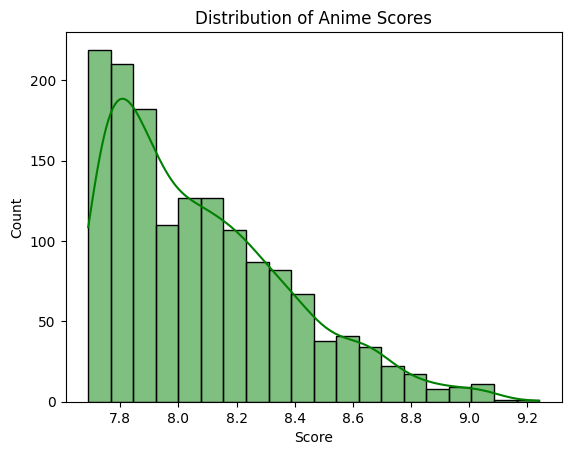

In [156]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.histplot(df['Score'], bins=20, kde=True,color="green")
plt.title('Distribution of Anime Scores')
plt.show()


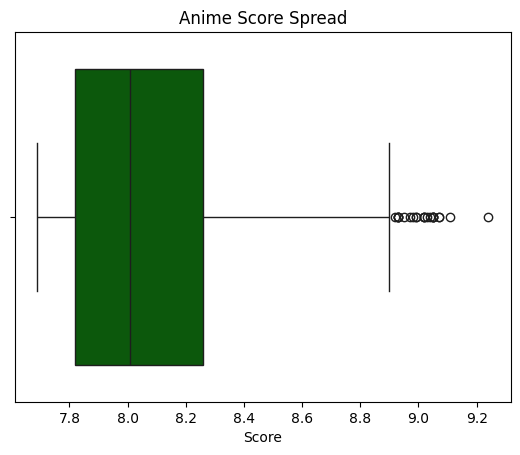

In [157]:

sns.boxplot(x=df['Score'],color="darkgreen")
plt.title('Anime Score Spread')
plt.show()

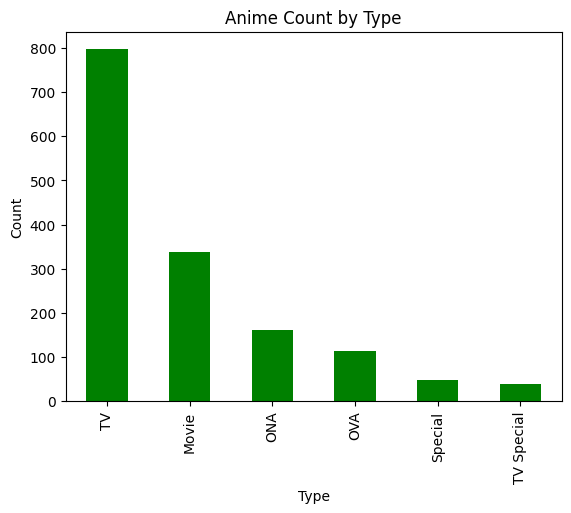

In [158]:


df['Type'].value_counts().plot(kind='bar',color="green")
plt.title('Anime Count by Type')
plt.ylabel('Count')
plt.show()

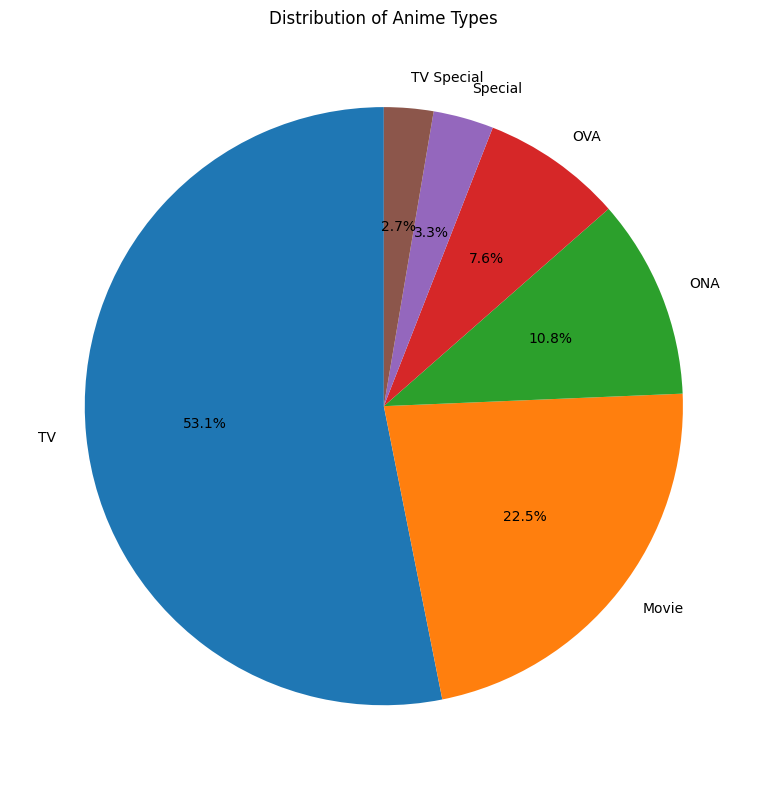

In [159]:
import matplotlib.pyplot as plt

type_counts = df['Type'].value_counts()

plt.figure(figsize=(8, 8))
plt.pie(
    type_counts,
    labels=type_counts.index,
    autopct='%1.1f%%',
    startangle=90
)
plt.title('Distribution of Anime Types')
plt.tight_layout()
plt.show()

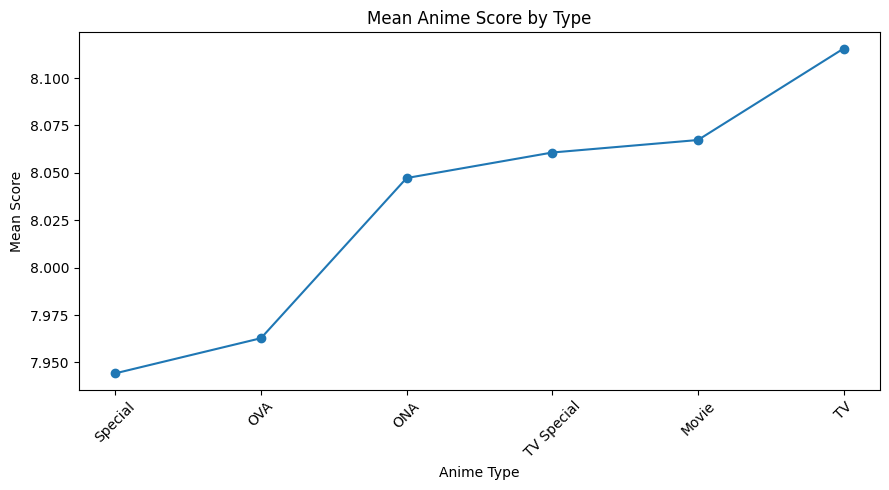

In [160]:
mean_scores = df.groupby('Type', observed=True)['Score'].mean().sort_values()

plt.figure(figsize=(9, 5))
plt.plot(mean_scores.index, mean_scores.values, marker='o')
plt.xlabel('Anime Type')
plt.ylabel('Mean Score')
plt.title('Mean Anime Score by Type')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

What we can conclude
- Score histogram: most anime scores fall around 7.7–8.3, with fewer anime scoring above 8.5.
- Score boxplot: the upper-end scores are outliers by the IQR rule. Don't remove them automatically; high scores are valid observations.
- Anime count by type: TV anime dominate the dataset, followed by movies. Your data is imbalanced across formats.
- Descriptive statistics: the median episode count is 12, while the mean is about 19. This suggests some very long series pull the mean upward.

## Correlation

Pearson correlation:
0.005690578830095247
Spearman correlation:
0.08081632777437783


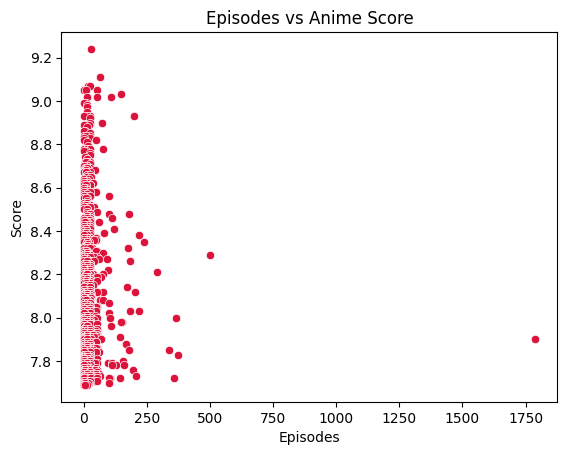

In [161]:
# Correlation between episode count and anime score
corr_data = df[['Episodes', 'Score']].dropna()

print("Pearson correlation:")
print(corr_data['Episodes'].corr(corr_data['Score'], method='pearson'))

print("Spearman correlation:")
print(corr_data['Episodes'].corr(corr_data['Score'], method='spearman'))

sns.scatterplot(data=corr_data, x='Episodes', y='Score',color="crimson")
plt.title('Episodes vs Anime Score')
plt.show()

What does this mean?
- Pearson ≈ 0: Anime episode count and score have virtually no linear relationship in your dataset.
- Spearman ≈ 0.081: There is a very weak tendency for anime with more episodes to have higher scores in rank-based terms, but the association is negligible.

In [162]:
from scipy.stats import pearsonr, spearmanr

episodes = corr_data['Episodes']
scores = corr_data['Score']

r, p_pearson = pearsonr(episodes, scores)
rho, p_spearman = spearmanr(episodes, scores)

print(f"Pearson r = {r:.4f}, p-value = {p_pearson:.4f}")
print(f"Spearman rho = {rho:.4f}, p-value = {p_spearman:.4f}")

Pearson r = 0.0057, p-value = 0.8267
Spearman rho = 0.0808, p-value = 0.0018


In [163]:
alpha=0.05
if p_pearson < alpha:
    print("Pearson correlation is statistically significant.")
else:
    print("Pearson correlation is not statistically significant.")

if p_spearman < alpha:
    print("Spearman correlation is statistically significant.")
else:
    print("Spearman correlation is not statistically significant.")

Pearson correlation is not statistically significant.
Spearman correlation is statistically significant.


Pearson: We fail to reject \(H_0\). There is insufficient evidence of a linear relationship between episode count and anime score.



Spearman: We reject \(H_0\). There is evidence of a positive monotonic association, but its strength is extremely weak.

## probability and conditional probability

In [164]:
# Probability of each anime type
print("P(Type):")
print(df['Type'].value_counts(normalize=True).round(3))


P(Type):
Type
TV            0.531
Movie         0.225
ONA           0.108
OVA           0.076
Special       0.033
TV Special    0.027
Name: proportion, dtype: float64


In [165]:

# Probability of score category given anime type
df['Score Category'] = pd.cut(
    df['Score'],
    bins=[-float('inf'), 8, 8.5, float('inf')],
    labels=['Below 8', '8 to 8.5', 'Above 8.5']
)

print("P(Score Category | Type):")
display(pd.crosstab(
    df['Type'],
    df['Score Category'],
    normalize='index',
    margins=True,
    margins_name='Total'

).round(3))

P(Score Category | Type):


Score Category,Below 8,8 to 8.5,Above 8.5
Type,,,
Movie,0.515,0.379,0.107
ONA,0.568,0.346,0.086
OVA,0.623,0.360,0.018
Special,0.673,0.327,0.000
TV,0.443,0.423,0.134
TV Special,0.525,0.350,0.125
Total,0.496,0.395,0.109


This covers marginal probability and conditional probability using your real dataset. We can then use the same contingency table for the chi-square test of independence.

What your results tell us
- TV anime make up 53.1% of the dataset, followed by movies at 22.5%.
- Across all anime, 49.6% score below 8, 39.5% score between 8 and 8.5, and 10.9% score above 8.5.
- TV anime have the largest proportion scoring above 8.5 (13.4%), followed by TV Specials (12.5%) and movies (10.7%).
- No Specials in your sample score above 8.5. This is an observation about your dataset, not a general rule about anime.
These are conditional proportions, not proof that anime type causes a higher or lower score.

## Chi-square test of independence

* Hnull: Anime type and score category are independent.
* Halt: Anime type and score category are associated.


In [166]:
from scipy.stats import chi2_contingency

table = pd.crosstab(df['Type'], df['Score Category'])

chi2, p, dof, expected = chi2_contingency(table)

print(f"Chi-square statistic: {chi2:.4f}")
print(f"Degrees of freedom: {dof}")
print(f"P-value: {p:.6f}")
print("Decision:", "Reject H0" if p < 0.05 else "Fail to reject H0")


Chi-square statistic: 36.8333
Degrees of freedom: 10
P-value: 0.000060
Decision: Reject H0


In [167]:
print("Expected frequencies:")
display(pd.DataFrame(expected, index=table.index, columns=table.columns).round(2))

Expected frequencies:


Score Category,Below 8,8 to 8.5,Above 8.5
Type,,,
Movie,167.65,133.40,36.95
ONA,80.35,63.94,17.71
OVA,56.54,44.99,12.46
Special,24.30,19.34,5.36
TV,395.31,314.55,87.14
TV Special,19.84,15.79,4.37


In [168]:
print("Cells with expected frequency < 5:", (expected < 5).sum())
print("Total cells:", expected.size)
print("Percentage below 5:", round((expected < 5).mean() * 100, 2), "%")

Cells with expected frequency < 5: 1
Total cells: 18
Percentage below 5: 5.56 %


Only 1 out of 18 cells (5.56%) has an expected frequency below 5, and none are below 1. The chi-square approximation is generally considered acceptable under the common rule of thumb.

Record this result for your practical:
- Conclusion: Anime type and score category are significantly associated in this dataset.
- Chi-square: 36.8333
- df: 10
- p-value: 0.000060
- Decision: Reject \(H_0\) at \(\alpha=0.05\).

## Sampling methods + CLT

In [169]:
# Sampling methods using anime scores
scores = df.dropna(subset=['Score']).copy()
n = 100

# 1. Simple random sample
random_sample = scores.sample(n=n, random_state=42)


In [170]:

# 2. Systematic sample
shuffled = scores.sample(frac=1, random_state=42).reset_index(drop=True)
step = len(shuffled) // n
systematic_sample = shuffled.iloc[::step].head(n)


In [171]:

# 3. Stratified sample by anime type
stratified_sample = (
    scores.groupby('Type', group_keys=False)
    .apply(lambda group: group.sample(
        n=max(1, round(n * len(group) / len(scores))),
        random_state=42
    ))
)

print("Dataset mean:", scores['Score'].mean())
print("Random sample mean:", random_sample['Score'].mean())
print("Systematic sample mean:", systematic_sample['Score'].mean())
print("Stratified sample mean:", stratified_sample['Score'].mean())

Dataset mean: 8.078660000000001
Random sample mean: 8.068200000000001
Systematic sample mean: 8.0901
Stratified sample mean: 8.052673267326734


/tmp/ipykernel_1284/3978541031.py:4: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda group: group.sample(


r three sampling methods all produced means close to the full dataset mean of 8.0787, which suggests they’re giving reasonable estimates for this sample.

## CLT

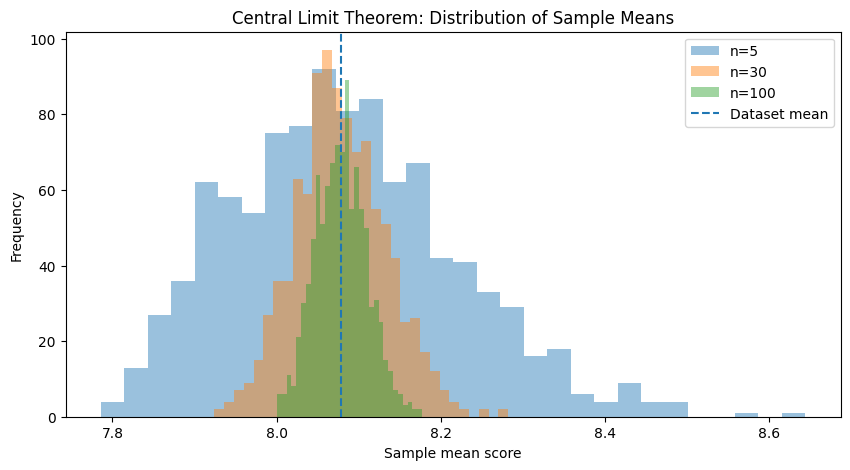

In [172]:
import numpy as np
import matplotlib.pyplot as plt

scores = df['Score'].dropna()
sample_means = {}

for n in [5, 30, 100]:
    means = [
        scores.sample(n=n, replace=True).mean()
        for _ in range(1000)
    ]
    sample_means[n] = means

plt.figure(figsize=(10, 5))
for n, means in sample_means.items():
    plt.hist(means, bins=30, alpha=0.45, label=f'n={n}')

plt.axvline(scores.mean(), linestyle='--', label='Dataset mean')
plt.xlabel('Sample mean score')
plt.ylabel('Frequency')
plt.title('Central Limit Theorem: Distribution of Sample Means')
plt.legend()
plt.show()

## CI : confidence interval

In [173]:
#We'll estimate a range that could contain the true mean anime score, rather than just a single estimate.
from scipy import stats
import numpy as np

scores = df['Score'].dropna()
n = len(scores)
mean = scores.mean()
se = stats.sem(scores)

ci = stats.t.interval(
    confidence=0.95,
    df=n - 1,
    loc=mean,
    scale=se
)

print(f"Sample mean: {mean:.4f}")
print(f"95% Confidence Interval: ({ci[0]:.4f}, {ci[1]:.4f})")
print(f"Margin of error: {(ci[1] - ci[0]) / 2:.4f}")

Sample mean: 8.0787
95% Confidence Interval: (8.0631, 8.0942)
Margin of error: 0.0156


## Confidence interval coverage probability

In [174]:
import numpy as np
from scipy.stats import t

population = df['Score'].dropna().to_numpy()
population_mean = population.mean()

rng = np.random.default_rng(42)
n_samples = 1000
sample_size = 30
covered = 0

for _ in range(n_samples):
    sample = rng.choice(population, size=sample_size, replace=True)
    sample_mean = sample.mean()
    se = sample.std(ddof=1) / np.sqrt(sample_size)
    margin = t.ppf(0.975, df=sample_size - 1) * se

    lower = sample_mean - margin
    upper = sample_mean + margin

    if lower <= population_mean <= upper:
        covered += 1

coverage = covered / n_samples

print(f"Reference population mean: {population_mean:.4f}")
print(f"Empirical 95% CI coverage: {coverage:.3f}")
print(f"Coverage percentage: {coverage * 100:.1f}%")

Reference population mean: 8.0787
Empirical 95% CI coverage: 0.941
Coverage percentage: 94.1%


## Hypothesis testing

In [175]:
from scipy.stats import ttest_ind

tv = df.loc[df['Type'] == 'TV', 'Score'].dropna()
movies = df.loc[df['Type'] == 'Movie', 'Score'].dropna()

t_stat, p_value = ttest_ind(tv, movies, equal_var=False)

print(f"TV mean score: {tv.mean():.4f}")
print(f"Movie mean score: {movies.mean():.4f}")
print(f"T-statistic: {t_stat:.4f}")
print(f"P-value: {p_value:.6f}")

if p_value < 0.05:
    print("Reject H0: The mean scores differ significantly.")
else:
    print("Fail to reject H0: Insufficient evidence of a difference.")

TV mean score: 8.1156
Movie mean score: 8.0673
T-statistic: 2.4300
P-value: 0.015361
Reject H0: The mean scores differ significantly.


## Bootstrap confidence interval

Bootstrap estimates uncertainty by repeatedly sampling observations with replacement. We'll use it to estimate a 95% confidence interval for the difference between TV and movie mean scores.

In [176]:
import numpy as np

tv_scores = tv.to_numpy()
movie_scores = movies.to_numpy()

rng = np.random.default_rng(42)
n_boot = 5000
differences = []

for _ in range(n_boot):
    tv_sample = rng.choice(tv_scores, size=len(tv_scores), replace=True)
    movie_sample = rng.choice(movie_scores, size=len(movie_scores), replace=True)
    differences.append(tv_sample.mean() - movie_sample.mean())

lower, upper = np.percentile(differences, [2.5, 97.5])

print(f"Observed mean difference: {tv_scores.mean() - movie_scores.mean():.4f}")
print(f"95% Bootstrap CI: ({lower:.4f}, {upper:.4f})")

Observed mean difference: 0.0482
95% Bootstrap CI: (0.0098, 0.0865)


## one way anova

In [226]:
from scipy.stats import f_oneway

groups = [
    group['Score'].dropna().values
    for _, group in df.groupby('Type')
]

f_stat, p_value = f_oneway(*groups)

print(f"F-statistic: {f_stat:.4f}")
print(f"P-value: {p_value:.6f}")

if p_value < 0.05:
    print("Reject H0: At least one anime type has a different mean score.")
else:
    print("Fail to reject H0: Insufficient evidence of a difference.")

F-statistic: 8.0290
P-value: 0.000000
Reject H0: At least one anime type has a different mean score.


ANOVA only establishes that at least one group mean differs.

## one sample t test

In [178]:
from scipy.stats import ttest_1samp

scores = df['Score'].dropna()
benchmark = 8.0

t_stat, p_value = ttest_1samp(scores, popmean=benchmark)

print(f"Sample mean: {scores.mean():.4f}")
print(f"Benchmark mean: {benchmark:.2f}")
print(f"T-statistic: {t_stat:.4f}")
print(f"P-value: {p_value:.6f}")

if p_value < 0.05:
    print("Reject H0: Mean score differs significantly from 8.0.")
else:
    print("Fail to reject H0: Insufficient evidence of a difference.")

Sample mean: 8.0787
Benchmark mean: 8.00
T-statistic: 9.8975
P-value: 0.000000
Reject H0: Mean score differs significantly from 8.0.


## Z test demo with dataset std

In [179]:

#in one-sample Z-test, we need a known population standard deviation.
#Since we don't have one, we'll use the dataset's standard deviation as an approximation for a demonstration.

from scipy.stats import norm
import numpy as np

scores = df['Score'].dropna()
mu0 = 8.0
sigma = scores.std(ddof=0)  # Approximation, not a known population SD
n = len(scores)

z_stat = (scores.mean() - mu0) / (sigma / np.sqrt(n))
p_value = 2 * (1 - norm.cdf(abs(z_stat)))

print(f"Z-statistic: {z_stat:.4f}")
print(f"P-value: {p_value:.6f}")

Z-statistic: 9.9008
P-value: 0.000000


## coulld not do : paired t test

## Cluster sampling

In [180]:
import numpy as np

rng = np.random.default_rng(42)

types = df['Type'].dropna().unique()
selected_types = rng.choice(types, size=2, replace=False)

cluster_sample = df[df['Type'].isin(selected_types)]

print("Selected clusters:", selected_types)
print("Sample size:", len(cluster_sample))
print(f"Sample mean score: {cluster_sample['Score'].mean():.4f}")
print(f"Dataset mean score: {df['Score'].mean():.4f}")

Selected clusters: ['TV' 'TV Special']
Sample size: 837
Sample mean score: 8.1130
Dataset mean score: 8.0787


## comparing sampling results

In [181]:
sampling_results = {
    'Full dataset': scores.mean(),
    'Simple random': random_sample['Score'].mean(),
    'Systematic': systematic_sample['Score'].mean(),
    'Stratified': stratified_sample['Score'].mean(),
    'Cluster': cluster_sample['Score'].mean()
}

sampling_comparison = pd.DataFrame({
    'Method': sampling_results.keys(),
    'Mean Score': sampling_results.values()
})

sampling_comparison['Absolute Error'] = (
    sampling_comparison['Mean Score'] - scores.mean()
).abs()

sampling_comparison

,Method,Mean Score,Absolute Error
0,Full dataset,8.078660,0.000000
1,Simple random,8.068200,0.010460
2,Systematic,8.090100,0.011440
3,Stratified,8.052673,0.025987
4,Cluster,8.112951,0.034291


## Probability of each score category

In [182]:
score_probabilities = df['Score Category'].value_counts(normalize=True).sort_index()

print(score_probabilities)
print(f"\nSum of probabilities: {score_probabilities.sum():.4f}")

Score Category
Below 8      0.496000
8 to 8.5     0.394667
Above 8.5    0.109333
Name: proportion, dtype: float64

Sum of probabilities: 1.0000


## Compare score distribution with normal and uniform distributions

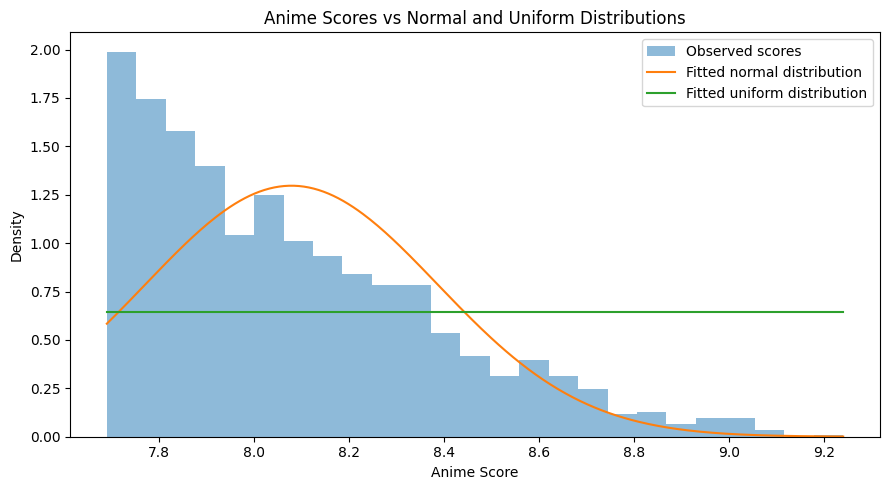

In [183]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm, uniform

scores = df['Score'].dropna().to_numpy()

x = np.linspace(scores.min(), scores.max(), 300)

plt.figure(figsize=(9, 5))
plt.hist(scores, bins=25, density=True, alpha=0.5, label='Observed scores')

plt.plot(
    x, norm.pdf(x, scores.mean(), scores.std(ddof=0)),
    label='Fitted normal distribution'
)

plt.plot(
    x, uniform.pdf(x, scores.min(), scores.max() - scores.min()),
    label='Fitted uniform distribution'
)

plt.xlabel('Anime Score')
plt.ylabel('Density')
plt.title('Anime Scores vs Normal and Uniform Distributions')
plt.legend()
plt.tight_layout()
plt.show()

## Simulated binomial distribution

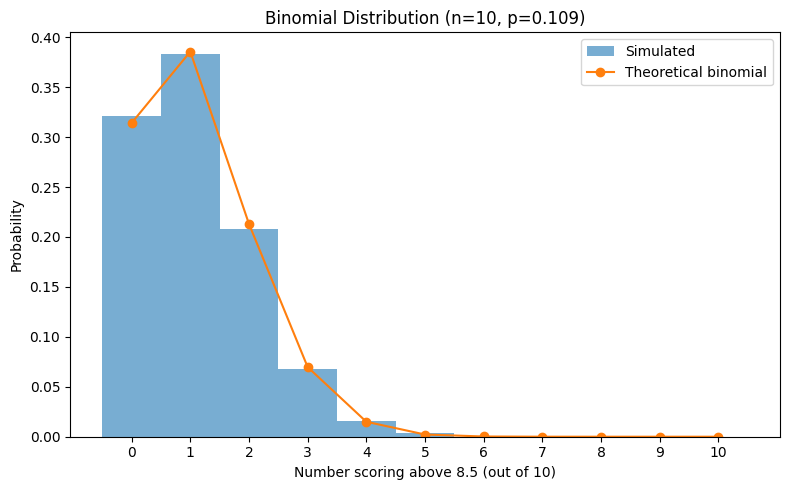

Estimated success probability: 0.1093


In [184]:
from scipy.stats import binom

p = (df['Score'] > 8.5).mean()
n = 10
simulated_counts = np.random.default_rng(42).binomial(n, p, size=5000)

values = np.arange(n + 1)

plt.figure(figsize=(8, 5))
plt.hist(
    simulated_counts,
    bins=np.arange(-0.5, n + 1.5, 1),
    density=True,
    alpha=0.6,
    label='Simulated'
)
plt.plot(values, binom.pmf(values, n, p), 'o-', label='Theoretical binomial')

plt.xlabel('Number scoring above 8.5 (out of 10)')
plt.ylabel('Probability')
plt.title(f'Binomial Distribution (n={n}, p={p:.3f})')
plt.xticks(values)
plt.legend()
plt.tight_layout()
plt.show()

print(f"Estimated success probability: {p:.4f}")

## conditional probablity

In [185]:
high_score = df['Score'] > 8.5

conditional_probability = (
    df.assign(High_Score=high_score)
      .groupby('Type', observed=True)['High_Score']
      .mean()
)

print("P(Score > 8.5 | Anime Type):")
print(conditional_probability.round(4))

P(Score > 8.5 | Anime Type):
Type
Movie         0.1065
ONA           0.0864
OVA           0.0175
Special       0.0000
TV            0.1343
TV Special    0.1250
Name: High_Score, dtype: float64


# Recommendation engine

In [191]:

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import normalize

# Normalize metadata
for col in ['Genres', 'Themes', 'Description', 'Type']:
    anime_df[col] = anime_df[col].fillna('').astype(str).str.strip()

# Separate feature groups so each can be weighted deliberately
genre_tfidf = TfidfVectorizer(
    tokenizer=lambda x: [g.strip().lower() for g in x.split(',') if g.strip()],
    token_pattern=None,
    lowercase=False
)

theme_tfidf = TfidfVectorizer(
    tokenizer=lambda x: [t.strip().lower() for t in x.split(',') if t.strip()],
    token_pattern=None,
    lowercase=False
)

description_tfidf = TfidfVectorizer(
    stop_words='english',
    max_features=10000,
    min_df=2,
    ngram_range=(1, 2),
    max_df=0.85
)

genre_matrix = genre_tfidf.fit_transform(anime_df['Genres'])
theme_matrix = theme_tfidf.fit_transform(anime_df['Themes'])
description_matrix = description_tfidf.fit_transform(anime_df['Description'])

# Give structured metadata more influence than plot descriptions
from scipy.sparse import hstack

feature_matrix = hstack([
    genre_matrix * 2.5,
    theme_matrix * 3.0,
    description_matrix * 0.5
]).tocsr()

feature_matrix = normalize(feature_matrix)

nn_model = NearestNeighbors(metric='cosine', algorithm='brute')
nn_model.fit(feature_matrix)

print("Improved recommendation model ready!")
print("Feature matrix shape:", feature_matrix.shape)


Improved recommendation model ready!
Feature matrix shape: (1500, 10071)


## Anime recommendation function

In [202]:

def recommend_anime(title, n=10, exclude_franchise=False):
    query = title.strip().casefold()

    if query not in title_lookup:
        print(f"Title not found: {title}")
        return pd.DataFrame()

    idx = title_lookup[query]
    source = anime_df.iloc[idx]

    distances, indices = nn_model.kneighbors(
        feature_matrix[idx],
        n_neighbors=len(anime_df)
    )

    # Use the first meaningful part of the title as the franchise name.
    # Example: "Attack on Titan" remains "attack on titan".
    franchise = query

    results = []

    for distance, i in zip(distances[0], indices[0]):
        if i == idx:
            continue

        row = anime_df.iloc[i]
        candidate = str(row['Title']).strip()

        if not candidate:
            continue

        # Exclude titles that contain the source title
        if exclude_franchise and franchise in candidate.casefold():
            continue

        score = pd.to_numeric(row.get('Score'), errors='coerce')
        similarity = 1 - distance

        results.append({
            'Title': candidate,
            'Type': row.get('Type', ''),
            'Genres': row.get('Genres', ''),
            'Themes': row.get('Themes', ''),
            'Score': score,
            'Similarity (%)': round(similarity * 100, 2)
        })

        if len(results) >= n:
            break

    return pd.DataFrame(results)


## testing the recommendation


In [209]:
display(
    recommend_anime(
        'Attack on Titan',
        n=10,
        exclude_franchise=True
    )
)


,Title,Type,Genres,Themes,Score,Similarity (%)
0,Astra Lost in Space,TV,"Adventure, Award Winning, Mystery, Sci-Fi, Sus...","Space, Survival",8.07,57.84
1,Fullmetal Alchemist,TV,"Action, Adventure, Award Winning, Drama, Fantasy",Military,8.12,52.66
2,Jin-Roh: The Wolf Brigade,Movie,"Action, Award Winning, Drama, Romance, Suspense","Adult Cast, Military, Psychological",7.78,52.38
3,The Promised Neverland,TV,"Mystery, Suspense","Psychological, Survival",8.46,52.02
4,Gnosia,TV,"Sci-Fi, Suspense","Space, Survival, Time Travel",7.82,45.46
5,Your Name.,Movie,"Award Winning, Drama",,8.82,45.24
6,Violet Evergarden: The Movie,Movie,"Award Winning, Drama",,8.83,45.24
7,La Maison en Petits Cubes,Movie,"Award Winning, Drama",,7.99,45.23
8,Tokyo Magnitude 8.0,TV,"Award Winning, Drama",,8.00,45.21
9,A Silent Voice,Movie,"Award Winning, Drama",,8.93,45.19


In [212]:
display(
    recommend_anime(
        'Ansatsu Kyoushitsu',
        n=10,
        exclude_franchise=True
    )
)

Title not found: Ansatsu Kyoushitsu


""


## Regression models

In [213]:

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split

# Start from the corrected dataset
ml_df = df.copy()

# Keep valid target values
ml_df['Score'] = pd.to_numeric(ml_df['Score'], errors='coerce')
ml_df = ml_df.dropna(subset=['Score']).copy()

# Numeric feature
ml_df['Episodes'] = pd.to_numeric(ml_df['Episodes'], errors='coerce')

# Text/categorical features
for col in ['Genres', 'Themes', 'Description',
            'Type', 'Status', 'Demographics']:
    ml_df[col] = ml_df[col].fillna('').astype(str).str.strip()

# Predict score using metadata only
feature_columns = [
    'Genres', 'Themes', 'Description',
    'Type', 'Status', 'Demographics', 'Episodes'
]

X = ml_df[feature_columns]
y = ml_df['Score']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Dataset size:", len(ml_df))
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Features:", feature_columns)
print("Target: Score")


Dataset size: 1500
Training records: 1200
Testing records: 300
Features: ['Genres', 'Themes', 'Description', 'Type', 'Status', 'Demographics', 'Episodes']
Target: Score


In [214]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Convert text metadata into TF-IDF features,
# categorical fields into one-hot features,
# and Episodes into an imputed numeric feature.
preprocessor = ColumnTransformer(
    transformers=[
        ('genres', TfidfVectorizer(), 'Genres'),
        ('themes', TfidfVectorizer(), 'Themes'),
        ('description', TfidfVectorizer(
            max_features=10000,
            stop_words='english',
            min_df=2
        ), 'Description'),
        ('categorical', OneHotEncoder(handle_unknown='ignore'),
         ['Type', 'Status', 'Demographics']),
        ('episodes', SimpleImputer(strategy='median'), ['Episodes'])
    ]
)

models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(alpha=1.0),
    'Lasso Regression': Lasso(alpha=0.001, max_iter=10000),
    'Decision Tree': DecisionTreeRegressor(
        max_depth=12, random_state=42
    ),
    'Random Forest': RandomForestRegressor(
        n_estimators=200,
        max_depth=15,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    )
}

trained_models = {}
results = []

for name, model in models.items():
    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('model', model)
    ])

    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)

    trained_models[name] = pipeline

    results.append({
        'Model': name,
        'MAE': mean_absolute_error(y_test, predictions),
        'RMSE': np.sqrt(mean_squared_error(y_test, predictions)),
        'R2': r2_score(y_test, predictions)
    })

results_df = pd.DataFrame(results).sort_values('RMSE')

display(results_df.round(4))


,Model,MAE,RMSE,R2
1,Ridge Regression,0.2114,0.2661,0.2086
4,Random Forest,0.2282,0.2803,0.1215
2,Lasso Regression,0.2343,0.2898,0.0610
3,Decision Tree,0.2440,0.3205,-0.1480
0,Linear Regression,0.6420,0.9141,-8.3396


In [219]:
from sklearn.model_selection import train_test_split

# Restore the numeric regression target
X = ml_df[feature_columns].copy()
y = pd.to_numeric(ml_df['Score'], errors='coerce')

# Keep only rows with valid numeric targets
valid = y.notna()
X = X.loc[valid]
y = y.loc[valid]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Target dtype:", y_train.dtype)
print("Example targets:", y_train.head().tolist())

Target dtype: float64
Example targets: [8.26, 8.14, 7.7, 7.83, 8.31]


In [222]:
import numpy as np
import pandas as pd  # Added missing import
from sklearn.base import clone
from sklearn.decomposition import TruncatedSVD
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.linear_model import Ridge, SGDRegressor  # Added missing Ridge import
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, KFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR

# SVR and SGD can work with the sparse text representation.
# Gradient Boosting uses SVD to reduce the high-dimensional features.
expanded_models = {
    "Ridge": Pipeline([("preprocessor", clone(preprocessor)), ("model", Ridge(alpha=10.0))]),
    "SVR (RBF)": Pipeline(
        [("preprocessor", clone(preprocessor)), ("model", SVR(kernel="rbf", C=1.0, epsilon=0.1))]
    ),
    "SGD Regressor": Pipeline(
        [
            ("preprocessor", clone(preprocessor)),
            ("scale", StandardScaler(with_mean=False)),
            (
                "model",
                SGDRegressor(
                    loss="squared_error",
                    penalty="l2",
                    alpha=0.001,
                    learning_rate="adaptive",
                    eta0=0.0001,
                    max_iter=10000,
                    tol=1e-4,
                    random_state=42,
                    early_stopping=True,
                ),
            ),
        ]
    ),
    "Gradient Boosting + SVD": Pipeline(
        [
            ("preprocessor", clone(preprocessor)),
            ("svd", TruncatedSVD(n_components=100, random_state=42)),
            (
                "model",
                GradientBoostingRegressor(
                    n_estimators=150, learning_rate=0.05, max_depth=2, random_state=42
                ),
            ),
        ]
    ),
}

expanded_results = []
expanded_trained_models = {}

for name, pipeline in expanded_models.items():
    pipeline.fit(X_train, y_train)
    pred = pipeline.predict(X_test)

    expanded_trained_models[name] = pipeline
    expanded_results.append(
        {
            "Model": name,
            "MAE": mean_absolute_error(y_test, pred),
            "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
            "R2": r2_score(y_test, pred),
        }
    )

expanded_results_df = pd.DataFrame(expanded_results).sort_values("RMSE")
display(expanded_results_df.round(4))


,Model,MAE,RMSE,R2
0,Ridge,0.2224,0.2755,0.1514
3,Gradient Boosting + SVD,0.2291,0.2774,0.1397
1,SVR (RBF),0.2333,0.2943,0.0317
2,SGD Regressor,0.5762,0.8117,-6.3647


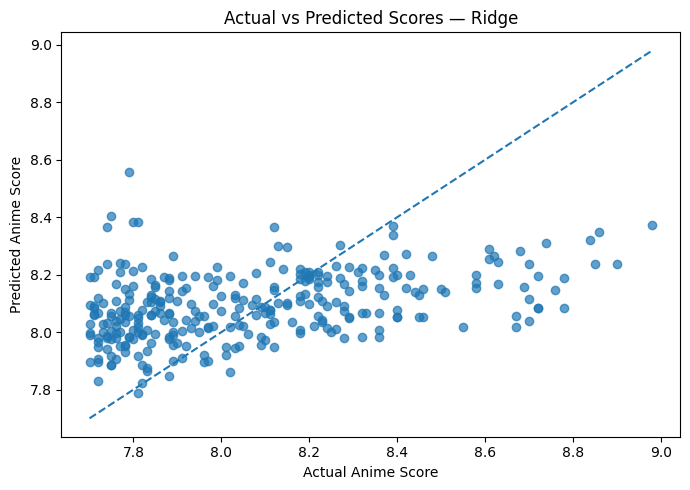

Model: Ridge
MAE: 0.2224
RMSE: 0.2755
R2: 0.1514


In [225]:

import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Match the plot to the model you are actually exporting
best_model_name = 'Ridge'
best_model = expanded_trained_models[best_model_name]

predictions = best_model.predict(X_test)

plt.figure(figsize=(7, 5))
plt.scatter(y_test, predictions, alpha=0.7)
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--'
)
plt.xlabel('Actual Anime Score')
plt.ylabel('Predicted Anime Score')
plt.title(f'Actual vs Predicted Scores — {best_model_name}')
plt.tight_layout()
plt.show()

print("Model:", best_model_name)
print("MAE:", round(mean_absolute_error(y_test, predictions), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, predictions)), 4))
print("R2:", round(r2_score(y_test, predictions), 4))


# Exporting the best model

In [223]:

import joblib
from pathlib import Path

# Prefer the tuned Ridge model if you ran cross-validation.
if 'best_ridge' in globals():
    final_model = best_ridge
else:
    final_model = expanded_trained_models['Ridge']

# Export fitted model and expected input-column order
joblib.dump(final_model, 'anistat_score_regressor.joblib')
joblib.dump(feature_columns, 'anistat_feature_columns.joblib')

print("Exported model: anistat_score_regressor.joblib")
print("Exported feature list: anistat_feature_columns.joblib")


Exported model: anistat_score_regressor.joblib
Exported feature list: anistat_feature_columns.joblib


In [230]:
# Export the current dataframe to a CSV file and trigger download
from google.colab import files

output_filename = 'myanimelist_cleaned.csv'
df.to_csv(output_filename, index=False)
print(f'Successfully saved dataframe to {output_filename}. Downloading now...')
files.download(output_filename)

Successfully saved dataframe to myanimelist_cleaned.csv. Downloading now...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>